In [1]:
import os

import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
spark = SparkSession.builder \
    .appName("AirQualityJoin") \
    .master("local[*]") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.session.timeZone", "UTC") \
    .config("spark.sql.redaction.string.regex", "file:/\\S*/data") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

PROCESSED = "../data/processed"
POLLUTANTS = ["pm25", "pm10", "no2", "o3"]
LOCAL_TZ = "Europe/Paris"
MIN_DAILY_HOURS = 18
MIN_COVERAGE = 0.75

steps = []


def log_step(step, before, after):
    steps.append((step, before, after))
    print(f"{step}: before = {before}, after = {after}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/18 13:24:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Load the clean tables

In [2]:
openaq_clean = spark.read.parquet(PROCESSED + "/openaq_clean")
weather_clean = spark.read.parquet(PROCESSED + "/weather_clean")
stations_clean = spark.read.parquet(PROCESSED + "/stations_clean")

openaq_rows = openaq_clean.count()
print("openaq_clean rows:", openaq_rows)
print("weather_clean rows:", weather_clean.count())
print("stations_clean rows:", stations_clean.count())

openaq_clean rows: 8516497
weather_clean rows: 8076600
stations_clean rows: 105


## Join pollution and weather on station and UTC hour

In [3]:
openaq = openaq_clean.drop("department", "region")
weather = weather_clean.drop("year")

openaq_weather = openaq.join(weather, ["location_id", "datetime_utc"], "inner")
joined_rows = openaq_weather.count()
log_step("Join with weather (inner)", openaq_rows, joined_rows)
print("OpenAQ rows without weather:", openaq_rows - joined_rows)

weather_period = weather.agg(F.min("datetime_utc").alias("weather_start"), F.max("datetime_utc").alias("weather_end"))
weather_period.show()

weather_stations = weather.select("location_id").distinct().withColumn("has_weather", F.lit(True))
no_weather = openaq.join(weather, ["location_id", "datetime_utc"], "left_anti") \
    .join(weather_stations, "location_id", "left") \
    .crossJoin(weather_period.select("weather_end")) \
    .withColumn("reason", F.when(F.col("has_weather").isNull(), "station without weather")
                .when(F.col("datetime_utc") > F.col("weather_end"), "after the end of the weather series")
                .otherwise("hour missing in the weather series"))
no_weather.groupBy("reason").agg(
    F.count("*").alias("rows"),
    F.min("datetime_utc").alias("first_hour"),
    F.max("datetime_utc").alias("last_hour")
).show(truncate=False)

Join with weather (inner): before = 8516497, after = 8509524
OpenAQ rows without weather: 6973
+-------------------+-------------------+
|      weather_start|        weather_end|
+-------------------+-------------------+
|2018-01-01 00:00:00|2026-10-10 23:00:00|
+-------------------+-------------------+

+-----------------------------------+----+-------------------+-------------------+
|reason                             |rows|first_hour         |last_hour          |
+-----------------------------------+----+-------------------+-------------------+
|after the end of the weather series|6973|2026-10-11 00:00:00|2026-10-12 22:00:00|
+-----------------------------------+----+-------------------+-------------------+



## Add station and region with a broadcast join

In [4]:
stations = stations_clean.select("location_id", "station", "region")
hourly_stations = openaq_weather.join(F.broadcast(stations), "location_id")
hourly_stations.explain()

hourly_stations = hourly_stations.cache()
stations_rows = hourly_stations.count()
log_step("Join with stations (broadcast)", joined_rows, stations_rows)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [location_id#0, datetime_utc#2, parameter#1, value#3, site_id#4, year#7, temperature_2m#18, relative_humidity_2m#19, precipitation#20, wind_speed_ms#21, station#32, region#37]
   +- BroadcastHashJoin [location_id#0], [location_id#30], Inner, BuildRight, false
      :- Project [location_id#0, datetime_utc#2, parameter#1, value#3, site_id#4, year#7, temperature_2m#18, relative_humidity_2m#19, precipitation#20, wind_speed_ms#21]
      :  +- SortMergeJoin [location_id#0, datetime_utc#2], [location_id#16, datetime_utc#17], Inner
      :     :- Sort [location_id#0 ASC NULLS FIRST, datetime_utc#2 ASC NULLS FIRST], false, 0
      :     :  +- Exchange hashpartitioning(location_id#0, datetime_utc#2, 200), ENSURE_REQUIREMENTS, [plan_id=998]
      :     :     +- Filter (isnotnull(location_id#0) AND isnotnull(datetime_utc#2))
      :     :        +- FileScan parquet [location_id#0,parameter#1,datetime_utc#2,value#3,site_id#4,year#7]

Spark chose a **SortMergeJoin** for the weather (two large tables shuffled and sorted on location_id and datetime_utc) and a **BroadcastHashJoin** for the stations (105 rows copied to every task, no shuffle of the big table).

## One value per site, pollutant and hour

In [5]:
print("Sites with several regions:",
      stations_clean.groupBy("site_id").agg(F.countDistinct("region").alias("regions"))
      .filter(F.col("regions") > 1).count())

site_hourly = hourly_stations.groupBy("site_id", "region", "parameter", "datetime_utc").agg(
    F.avg("value").alias("value"),
    F.avg("temperature_2m").alias("temperature_2m"),
    F.avg("relative_humidity_2m").alias("relative_humidity_2m"),
    F.avg("precipitation").alias("precipitation"),
    F.avg("wind_speed_ms").alias("wind_speed_ms"),
    F.count("*").alias("merged_rows")
)

merged = site_hourly.filter(F.col("merged_rows") > 1)
merged.groupBy("site_id", "parameter").agg(F.count("*").alias("merged_hours")) \
    .orderBy("site_id", "parameter").show(50)
print("Hours with two identifiers of the same site:", merged.count())

site_rows = site_hourly.count()
log_step("One value per site, pollutant and hour", stations_rows, site_rows)
site_hourly = site_hourly.drop("merged_rows")

Sites with several regions: 0
+-------+---------+------------+
|site_id|parameter|merged_hours|
+-------+---------+------------+
|   3699|      no2|          19|
|   3699|       o3|          19|
|   3699|     pm10|          18|
|   3943|      no2|          49|
|   3943|       o3|          43|
|   3943|     pm10|          52|
|   3943|     pm25|          52|
|   4006|      no2|          19|
|   4006|       o3|          19|
|   4006|     pm10|          19|
|   4006|     pm25|          19|
|   4068|     pm10|          19|
|   4068|     pm25|          19|
|   4069|      no2|          12|
|   4069|     pm25|           8|
|   4088|      no2|          12|
|   4088|     pm10|          12|
|   4088|     pm25|          12|
|   4128|      no2|          48|
|   4128|       o3|          43|
|   4128|     pm10|          19|
|   4128|     pm25|          19|
|   4164|      no2|           5|
|   4164|       o3|           4|
|2162641|      no2|          33|
|2162641|     pm25|          32|
+-------+----

## Calendar and weather classes

OpenAQ timestamps mark the end of the measurement hour (08:00 = 07:00-08:00), so datetime_local, the calendar columns and the date of the daily weather use the start of the hour (datetime_utc - 1 hour) in Paris time, while datetime_utc stays the join key with the weather.

In [6]:
hourly = site_hourly \
    .withColumn("datetime_local", F.from_utc_timestamp(F.col("datetime_utc") - F.expr("INTERVAL 1 HOUR"), LOCAL_TZ)) \
    .withColumn("year", F.year("datetime_local")) \
    .withColumn("month", F.month("datetime_local")) \
    .withColumn("season", F.when(F.col("month").isin(12, 1, 2), "winter")
                .when(F.col("month").isin(3, 4, 5), "spring")
                .when(F.col("month").isin(6, 7, 8), "summer")
                .otherwise("autumn")) \
    .withColumn("day_of_week", F.dayofweek("datetime_local")) \
    .withColumn("is_weekend", F.col("day_of_week").isin(1, 7)) \
    .withColumn("hour", F.hour("datetime_local")) \
    .withColumn("temp_class", F.when(F.col("temperature_2m") < 5, "< 5")
                .when(F.col("temperature_2m") < 15, "5-15")
                .when(F.col("temperature_2m") < 25, "15-25")
                .otherwise(">= 25")) \
    .withColumn("wind_class", F.when(F.col("wind_speed_ms") < 2, "calm")
                .when(F.col("wind_speed_ms") <= 5, "moderate")
                .otherwise("strong")) \
    .withColumn("rain", F.col("precipitation") >= 0.1) \
    .select("site_id", "region", "parameter", "datetime_utc", "datetime_local", "year", "month", "season",
            "day_of_week", "is_weekend", "hour", "value", "temperature_2m", "relative_humidity_2m",
            "precipitation", "wind_speed_ms", "temp_class", "wind_class", "rain")

hourly.show(5)

+-------+------------------+---------+-------------------+-------------------+----+-----+------+-----------+----------+----+-----+--------------+--------------------+-------------+-------------+----------+----------+-----+
|site_id|            region|parameter|       datetime_utc|     datetime_local|year|month|season|day_of_week|is_weekend|hour|value|temperature_2m|relative_humidity_2m|precipitation|wind_speed_ms|temp_class|wind_class| rain|
+-------+------------------+---------+-------------------+-------------------+----+-----+------+-----------+----------+----+-----+--------------+--------------------+-------------+-------------+----------+----------+-----+
|   2681|             Paris|      no2|2018-05-13 09:00:00|2018-05-13 10:00:00|2018|    5|spring|          1|      true|  10|40.75|          11.2|                81.0|          0.0|         2.92|      5-15|  moderate|false|
|   2681|             Paris|     pm10|2024-02-15 18:00:00|2024-02-15 18:00:00|2024|    2|winter|          5|

## Write analysis_hourly

In [7]:
hourly.repartition("year").write.mode("overwrite").partitionBy("year").parquet(PROCESSED + "/analysis_hourly")
hourly_stations.unpersist()

analysis_hourly = spark.read.parquet(PROCESSED + "/analysis_hourly")
analysis_hourly.printSchema()
hourly_rows = analysis_hourly.count()
print("Rows:", hourly_rows)

root
 |-- site_id: integer (nullable = true)
 |-- region: string (nullable = true)
 |-- parameter: string (nullable = true)
 |-- datetime_utc: timestamp (nullable = true)
 |-- datetime_local: timestamp (nullable = true)
 |-- month: integer (nullable = true)
 |-- season: string (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- is_weekend: boolean (nullable = true)
 |-- hour: integer (nullable = true)
 |-- value: double (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- wind_speed_ms: double (nullable = true)
 |-- temp_class: string (nullable = true)
 |-- wind_class: string (nullable = true)
 |-- rain: boolean (nullable = true)
 |-- year: integer (nullable = true)

Rows: 8508899


## Daily table

In [8]:
pollutant_days = analysis_hourly.withColumn("date", F.to_date("datetime_local")) \
    .groupBy("site_id", "region", "parameter", "date", "year", "month", "season", "day_of_week", "is_weekend") \
    .agg(F.round(F.avg("value"), 2).alias("value"), F.count("*").alias("hours")) \
    .cache()

days = pollutant_days.count()
log_step("Daily means per site, pollutant and local date", hourly_rows, days)

pollutant_days.groupBy("parameter").agg(
    F.count("*").alias("days"),
    F.sum(F.when(F.col("hours") >= MIN_DAILY_HOURS, 1).otherwise(0)).alias("kept"),
    F.sum(F.when(F.col("hours") < MIN_DAILY_HOURS, 1).otherwise(0)).alias("removed")
).orderBy("parameter").show()

complete_days = pollutant_days.filter(F.col("hours") >= MIN_DAILY_HOURS)
kept_days = complete_days.count()
print("Days kept:", kept_days, "removed:", days - kept_days)
log_step(f"Days with at least {MIN_DAILY_HOURS} hours", days, kept_days)

Daily means per site, pollutant and local date: before = 8508899, after = 447039
+---------+------+------+-------+
|parameter|  days|  kept|removed|
+---------+------+------+-------+
|      no2|153021|121058|  31963|
|       o3|109995| 86878|  23117|
|     pm10|112183| 70979|  41204|
|     pm25| 71840| 44211|  27629|
+---------+------+------+-------+

Days kept: 323126 removed: 123913
Days with at least 18 hours: before = 447039, after = 323126


In [9]:
site_weather = weather_clean.withColumnRenamed("location_id", "site_id") \
    .join(stations_clean.select("site_id").distinct(), "site_id", "left_semi")
daily_weather = site_weather \
    .withColumn("date", F.to_date(F.from_utc_timestamp(F.col("datetime_utc") - F.expr("INTERVAL 1 HOUR"), LOCAL_TZ))) \
    .groupBy("site_id", "date") \
    .agg(F.round(F.avg("temperature_2m"), 2).alias("temperature_mean"),
         F.round(F.sum("precipitation"), 2).alias("precipitation_total"),
         F.round(F.avg("wind_speed_ms"), 2).alias("wind_speed_mean"))

daily = complete_days.join(daily_weather, ["site_id", "date"])
daily.coalesce(1).write.mode("overwrite").parquet(PROCESSED + "/analysis_daily")
pollutant_days.unpersist()

analysis_daily = spark.read.parquet(PROCESSED + "/analysis_daily")
daily_rows = analysis_daily.count()
log_step("Join with the daily weather of the site", kept_days, daily_rows)
analysis_daily.orderBy("site_id", "parameter", "date").show(5)

Join with the daily weather of the site: before = 323126, after = 323126
+-------+----------+------+---------+----+-----+------+-----------+----------+-----+-----+----------------+-------------------+---------------+
|site_id|      date|region|parameter|year|month|season|day_of_week|is_weekend|value|hours|temperature_mean|precipitation_total|wind_speed_mean|
+-------+----------+------+---------+----+-----+------+-----------+----------+-----+-----+----------------+-------------------+---------------+
|   2681|2018-01-05| Paris|      no2|2018|    1|winter|          6|     false|75.62|   23|            9.08|                1.3|           4.79|
|   2681|2018-01-06| Paris|      no2|2018|    1|winter|          7|      true| 68.3|   19|            6.81|                0.2|           2.38|
|   2681|2018-01-07| Paris|      no2|2018|    1|winter|          1|      true|42.91|   24|            6.52|                2.4|           5.92|
|   2681|2018-01-08| Paris|      no2|2018|    1|winter|        

## Coverage per site, pollutant and year

In [10]:
period = analysis_hourly.agg(F.min("datetime_utc").alias("first_hour"), F.max("datetime_utc").alias("last_hour"))
period.show()

year_hours = period.select(F.explode(F.sequence("first_hour", "last_hour", F.expr("INTERVAL 1 HOUR"))).alias("datetime_utc")) \
    .groupBy(F.year(F.from_utc_timestamp(F.col("datetime_utc") - F.expr("INTERVAL 1 HOUR"), LOCAL_TZ)).alias("year")) \
    .agg(F.count("*").alias("year_hours"))
year_hours.orderBy("year").show()

coverage = analysis_hourly.groupBy("site_id", "region", "parameter", "year") \
    .agg(F.count("*").alias("hours")) \
    .join(year_hours, "year") \
    .withColumn("coverage", F.round(F.col("hours") / F.col("year_hours"), 3)) \
    .withColumn("well_covered", F.col("hours") >= MIN_COVERAGE * F.col("year_hours")) \
    .select("site_id", "region", "parameter", "year", "hours", "year_hours", "coverage", "well_covered")
coverage.coalesce(1).write.mode("overwrite").parquet(PROCESSED + "/coverage")

coverage = spark.read.parquet(PROCESSED + "/coverage")
log_step("Coverage per site, pollutant and year", hourly_rows, coverage.count())

print("Sites with data:")
coverage.groupBy("year").pivot("parameter", POLLUTANTS).count().fillna(0).orderBy("year").show()
print(f"Well covered sites (at least {MIN_COVERAGE:.0%} of the hours):")
coverage.groupBy("year").pivot("parameter", POLLUTANTS).agg(F.sum(F.col("well_covered").cast("int"))) \
    .fillna(0).orderBy("year").show()

+-------------------+-------------------+
|         first_hour|          last_hour|
+-------------------+-------------------+
|2018-01-05 01:00:00|2026-10-10 23:00:00|
+-------------------+-------------------+

+----+----------+
|year|year_hours|
+----+----------+
|2018|      8663|
|2019|      8760|
|2020|      8784|
|2021|      8760|
|2022|      8760|
|2023|      8760|
|2024|      8784|
|2025|      8760|
|2026|      6792|
+----+----------+

Coverage per site, pollutant and year: before = 8508899, after = 1542
Sites with data:
+----+----+----+---+---+
|year|pm25|pm10|no2| o3|
+----+----+----+---+---+
|2018|  21|  45| 61| 42|
|2019|  20|  43| 57| 41|
|2020|  19|  43| 57| 40|
|2021|  22|  42| 56| 40|
|2022|  27|  42| 56| 40|
|2023|  31|  39| 55| 39|
|2024|  37|  46| 61| 44|
|2025|  37|  48| 61| 44|
|2026|  37|  47| 59| 43|
+----+----+----+---+---+

Well covered sites (at least 75% of the hours):
+----+----+----+---+---+
|year|pm25|pm10|no2| o3|
+----+----+----+---+---+
|2018|   8|  24| 4

## Joined rows per month and pollutant

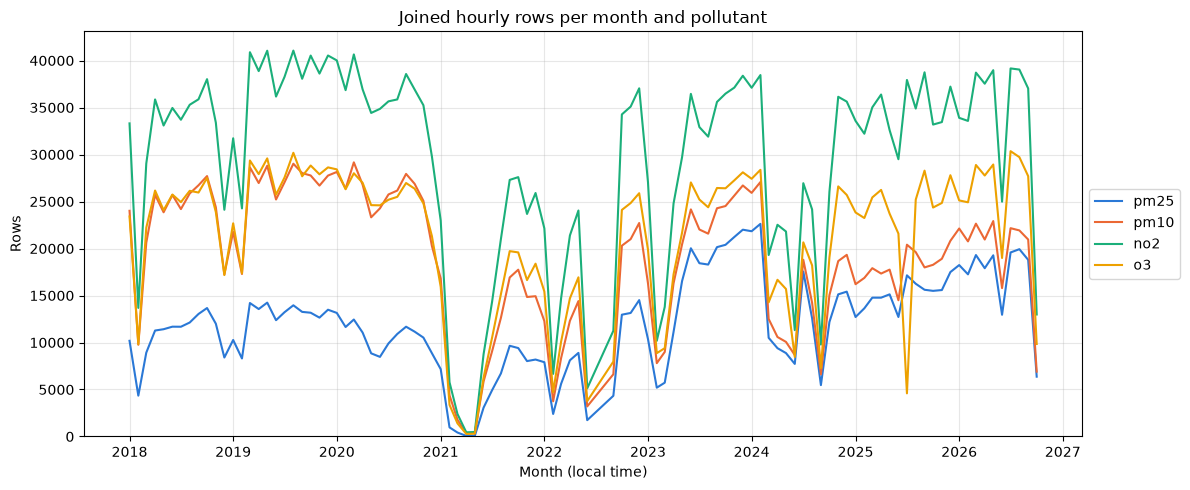

In [11]:
monthly = analysis_hourly.groupBy(F.trunc("datetime_local", "month").alias("month"), "parameter") \
    .count().orderBy("month").collect()
colors = {"pm25": "#2a78d6", "pm10": "#eb6834", "no2": "#1baf7a", "o3": "#eda100"}

fig, ax = plt.subplots(figsize=(12, 5))
for p in POLLUTANTS:
    points = [r for r in monthly if r["parameter"] == p]
    ax.plot([r["month"] for r in points], [r["count"] for r in points], color=colors[p], linewidth=1.5, label=p)
ax.set_title("Joined hourly rows per month and pollutant")
ax.set_xlabel("Month (local time)")
ax.set_ylabel("Rows")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## Summary of the join steps

In [12]:
summary = spark.createDataFrame(steps, ["step", "rows_before", "rows_after"])
summary.show(truncate=False)

+----------------------------------------------+-----------+----------+
|step                                          |rows_before|rows_after|
+----------------------------------------------+-----------+----------+
|Join with weather (inner)                     |8516497    |8509524   |
|Join with stations (broadcast)                |8509524    |8509524   |
|One value per site, pollutant and hour        |8509524    |8508899   |
|Daily means per site, pollutant and local date|8508899    |447039    |
|Days with at least 18 hours                   |447039     |323126    |
|Join with the daily weather of the site       |323126     |323126    |
|Coverage per site, pollutant and year         |8508899    |1542      |
+----------------------------------------------+-----------+----------+



## Stop Spark

In [13]:
spark.stop()